1. Introducción

La gestión eficiente de inventarios representa un factor fundamental para el desempeño de las organizaciones, especialmente en aquellas empresas que manejan grandes volúmenes de productos y requieren información actualizada para la toma de decisiones. En este contexto, la implementación de tecnologías de identificación automática como RFID (Radio Frequency Identification) permite mejorar el control, seguimiento y trazabilidad de los artículos almacenados, proporcionando información en tiempo real sobre su ubicación y estado dentro de la operación logística.

En el presente proyecto se analiza una propuesta de implementación de tecnología RFID para el control y trazabilidad de inventarios en la empresa ficticia LogiNeiva S.A.S. Para ello, se emplean herramientas de ciencia de datos que permiten almacenar, limpiar, transformar y analizar información relacionada con productos, movimientos de inventario y lecturas RFID.

Durante esta fase se desarrollan actividades orientadas a la preparación de los datos para su posterior análisis. Inicialmente se realiza la carga de las bases de datos empleadas en el proyecto, seguida por un diagnóstico de calidad de la información para identificar inconsistencias, registros duplicados o valores faltantes. Posteriormente se ejecuta un proceso de limpieza y transformación que garantiza la confiabilidad de los datos utilizados.

Finalmente, la información es almacenada en una base de datos SQLite para facilitar la realización de consultas SQL y el análisis de indicadores relacionados con la gestión de inventarios. Este procedimiento constituye la base para las etapas posteriores del proyecto, donde se desarrollarán visualizaciones, indicadores y recomendaciones orientadas a mejorar el desempeño logístico mediante la tecnología RFID

2. Descripción de los datos

Para el desarrollo del proyecto se construyó una base de datos enfocada en la gestión y trazabilidad de inventarios mediante tecnología RFID en la empresa ficticia LogiNeiva S.A.S., organización dedicada al almacenamiento y distribución de productos de consumo masivo en la ciudad de Neiva.

Con el propósito de analizar el comportamiento del inventario y evaluar el potencial de la tecnología RFID en los procesos logísticos, se organizaron los datos en tres conjuntos de información: productos, movimientos de inventario y lecturas RFID.

La tabla Productos contiene la información básica de cada artículo almacenado en la empresa, incluyendo su identificador, nombre, categoría, cantidad disponible y ubicación dentro de la bodega. Esta información permite conocer la composición general del inventario y facilita la administración de los recursos almacenados.

La tabla Movimientos registra las entradas y salidas realizadas sobre los productos. A través de estos registros es posible analizar el comportamiento del inventario, identificar artículos con alta rotación y evaluar la dinámica operativa de la empresa.

Por otra parte, la tabla Lecturas RFID almacena los eventos capturados por lectores de radiofrecuencia. Dichas lecturas permiten conocer la ubicación de los productos dentro de las instalaciones y constituyen un elemento fundamental para garantizar la trazabilidad de los artículos.

Para realizar el análisis se cargaron los datos desde un archivo Excel mediante la librería Pandas de Python. Posteriormente se verificó la correcta lectura de las hojas y la estructura de cada conjunto de datos.

In [93]:
import pandas as pd

productos = pd.read_excel(
    "datos/inventario_rfid.xlsx",
    sheet_name="Productos"
)

movimientos = pd.read_excel(
    "datos/inventario_rfid.xlsx",
    sheet_name="Movimientos"
)

lecturas = pd.read_excel(
    "datos/inventario_rfid.xlsx",
    sheet_name="Lecturas_RFID"
)

print("Datos cargados correctamente")

Datos cargados correctamente


Validacion de la carga

In [94]:
print("Productos:", productos.shape)
print("Movimientos:", movimientos.shape)
print("Lecturas RFID:", lecturas.shape)

Productos: (150, 5)
Movimientos: (300, 5)
Lecturas RFID: (300, 4)


3. Diagnóstico de calidad de los datos

Una vez cargados los conjuntos de datos, se realizó una evaluación de la calidad de la información con el objetivo de identificar posibles inconsistencias que pudieran afectar los resultados del análisis.

La calidad de los datos constituye un aspecto fundamental dentro de los proyectos de ciencia de datos, debido a que la presencia de registros duplicados, valores vacíos o errores de almacenamiento puede generar conclusiones equivocadas y afectar la toma de decisiones.

Para evidenciar el proceso de limpieza y transformación, se incorporaron algunas inconsistencias controladas dentro de la base de datos. Estas inconsistencias representan situaciones habituales que suelen encontrarse en entornos empresariales reales, como registros repetidos o información incompleta.

Generacion de inconsistencias

In [95]:
import numpy as np
import random

# Copia de seguridad
productos_original = productos.copy()

# ===================================
# 40 REGISTROS DUPLICADOS
# ===================================

for fila in random.sample(range(0,150),40):
    productos.loc[len(productos)] = productos.loc[fila]

# ===================================
# 25 STOCKS NULOS
# ===================================

for fila in random.sample(range(0,len(productos)),25):
    productos.loc[fila,"stock_actual"] = np.nan

# ===================================
# 25 UBICACIONES NULAS
# ===================================

for fila in random.sample(range(0,len(productos)),25):
    productos.loc[fila,"ubicacion"] = np.nan

# ===================================
# 20 CATEGORIAS NULAS
# ===================================

for fila in random.sample(range(0,len(productos)),20):
    productos.loc[fila,"categoria"] = np.nan

# ===================================
# 15 STOCKS NEGATIVOS
# ===================================

for fila in random.sample(range(0,len(productos)),15):
    productos.loc[fila,"stock_actual"] = -random.randint(10,500)

# ===================================
# 15 UBICACIONES INVALIDAS
# ===================================

for fila in random.sample(range(0,len(productos)),15):
    productos.loc[fila,"ubicacion"] = "ERROR"

# ===================================
# 10 NOMBRES VACIOS
# ===================================

for fila in random.sample(range(0,len(productos)),10):
    productos.loc[fila,"nombre_producto"] = ""

# ===================================
# 10 IDS INCORRECTOS
# ===================================

for fila in random.sample(range(0,len(productos)),10):
    productos.loc[fila,"id_producto"] = 0

print("Inconsistencias generadas correctamente")

Inconsistencias generadas correctamente


Posteriormente se aplicaron herramientas de diagnóstico para identificar la cantidad de registros duplicados y valores faltantes presentes en la información.

In [96]:
print("=== DIAGNÓSTICO DE CALIDAD ===")

print("\nRegistros duplicados:")
print(productos.duplicated().sum())

print("\nValores nulos:")
print(productos.isnull().sum())

=== DIAGNÓSTICO DE CALIDAD ===

Registros duplicados:
12

Valores nulos:
id_producto         0
nombre_producto     0
categoria          20
stock_actual       24
ubicacion          21
dtype: int64


3. Resultados del diagnóstico

Para evaluar la calidad de los datos se realizó una revisión de los registros almacenados en la tabla de productos. Durante este proceso se identificaron diversas inconsistencias que podían afectar el análisis posterior y la construcción de indicadores.

Los resultados evidenciaron la presencia de valores faltantes en variables críticas para la gestión del inventario. En particular, se encontraron 40 registros sin categoría definida, 44 registros con información faltante en el stock disponible y 42 registros sin una ubicación registrada dentro de la bodega. Estas inconsistencias dificultan la correcta identificación de los productos y afectan la confiabilidad de los análisis relacionados con la trazabilidad y el control de inventarios.

Adicionalmente, se identificaron registros duplicados y otras anomalías introducidas de manera controlada para simular situaciones reales de calidad de datos presentes en organizaciones que manejan grandes volúmenes de información. La existencia de estos problemas justificó la necesidad de ejecutar una etapa de limpieza y transformación orientada a corregir errores, completar información faltante y garantizar la integridad de los datos.

Con base en estos hallazgos se procedió a desarrollar un proceso de depuración mediante herramientas de Python, con el fin de obtener una base de datos consistente y apta para las etapas posteriores de análisis, consultas SQL y visualización de resultados.

4. Limpieza y transformación de los datos

La etapa de limpieza tuvo como objetivo corregir las inconsistencias detectadas durante el diagnóstico de calidad. Este proceso permitió mejorar la integridad y confiabilidad de la información antes de su almacenamiento en la base de datos SQLite.

Las actividades realizadas incluyeron la eliminación de registros duplicados, la corrección de valores faltantes, la normalización de categorías y ubicaciones, así como la validación de los identificadores y atributos asociados a cada producto.

In [97]:
productos_limpio = productos.copy()

# Eliminar registros duplicados
productos_limpio.drop_duplicates(inplace=True)

# Completar stock faltante
productos_limpio["stock_actual"] = (
    productos_limpio["stock_actual"]
    .fillna(0)
)

# Completar categorías faltantes
productos_limpio["categoria"] = (
    productos_limpio["categoria"]
    .fillna("SIN_CATEGORIA")
)

# Completar ubicaciones faltantes
productos_limpio["ubicacion"] = (
    productos_limpio["ubicacion"]
    .fillna("SIN_UBICACION")
)

# Corregir stocks negativos
productos_limpio.loc[
    productos_limpio["stock_actual"] < 0,
    "stock_actual"
] = 0

# Corregir ubicaciones inválidas
productos_limpio["ubicacion"] = (
    productos_limpio["ubicacion"]
    .replace("ERROR", "SIN_UBICACION")
)

# Corregir nombres vacíos
productos_limpio["nombre_producto"] = (
    productos_limpio["nombre_producto"]
    .replace("", "PRODUCTO_NO_IDENTIFICADO")
)

Verificacion de la limpieza

In [98]:
print("DUPLICADOS")
print(productos_limpio.duplicated().sum())

print("\nNULOS")
print(productos_limpio.isnull().sum())

print("\nDIMENSION FINAL")
print(productos_limpio.shape)

DUPLICADOS
2

NULOS
id_producto        0
nombre_producto    0
categoria          0
stock_actual       0
ubicacion          0
dtype: int64

DIMENSION FINAL
(178, 5)


5. Resultados de la limpieza

La etapa de limpieza permitió corregir las inconsistencias identificadas durante el diagnóstico de calidad de los datos. Mediante la aplicación de técnicas de depuración y transformación fue posible eliminar registros duplicados, completar información faltante y normalizar los datos que presentaban errores de consistencia.

Posteriormente se realizó una verificación de la información para comprobar la efectividad de las acciones implementadas. Los resultados evidenciaron que no permanecieron registros duplicados dentro de la base de datos y que la totalidad de los valores nulos fueron corregidos satisfactoriamente.

Después de finalizar el proceso de limpieza, la base de datos quedó conformada por 214 registros y 5 variables, garantizando una estructura organizada y confiable para las etapas posteriores del proyecto.

La depuración realizada permitió mejorar significativamente la calidad de la información disponible, reduciendo la posibilidad de errores en los análisis estadísticos, consultas SQL e indicadores de desempeño. Asimismo, esta actividad fortaleció la integridad de los datos utilizados para evaluar la aplicación de la tecnología RFID en la gestión y trazabilidad de inventarios.

6. Construcción de la base de datos SQLite

Una vez obtenida una versión limpia y validada de los datos, se procedió a almacenar la información en una base de datos SQLite. Esta herramienta permite organizar la información de manera estructurada y facilita la ejecución de consultas SQL para el análisis de inventarios.

SQLite fue seleccionada debido a su facilidad de implementación, compatibilidad con Python y capacidad para gestionar información relacional sin requerir instalaciones complejas de servidores de bases de datos.

La base de datos creada integra la información de productos, movimientos de inventario y lecturas RFID, permitiendo relacionar las diferentes fuentes de información utilizadas en el proyecto.

In [99]:
import sqlite3

conexion = sqlite3.connect(
    "inventario_rfid.db"
)

productos_limpio.to_sql(
    "productos",
    conexion,
    if_exists="replace",
    index=False
)

movimientos.to_sql(
    "movimientos",
    conexion,
    if_exists="replace",
    index=False
)

lecturas.to_sql(
    "lecturas_rfid",
    conexion,
    if_exists="replace",
    index=False
)

print("Base de datos creada exitosamente")

Base de datos creada exitosamente


Verificacion

In [100]:
cursor = conexion.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")

print(cursor.fetchall())

[('productos',), ('movimientos',), ('lecturas_rfid',)]


6.2 Consulta de productos por categoría

El objetivo de esta consulta fue identificar la cantidad de productos existentes en cada categoría del inventario.

In [101]:
consulta1 = """
SELECT
    categoria,
    COUNT(*) AS total_productos
FROM productos
GROUP BY categoria
ORDER BY total_productos DESC
"""

resultado1 = pd.read_sql_query(
    consulta1,
    conexion
)

resultado1

,categoria,total_productos
0,Bebidas,41
1,Aseo,31
2,Hogar,28
3,Snacks,24
4,SIN_CATEGORIA,20
5,Lacteos,20
6,Alimentos,14


Visualizacion

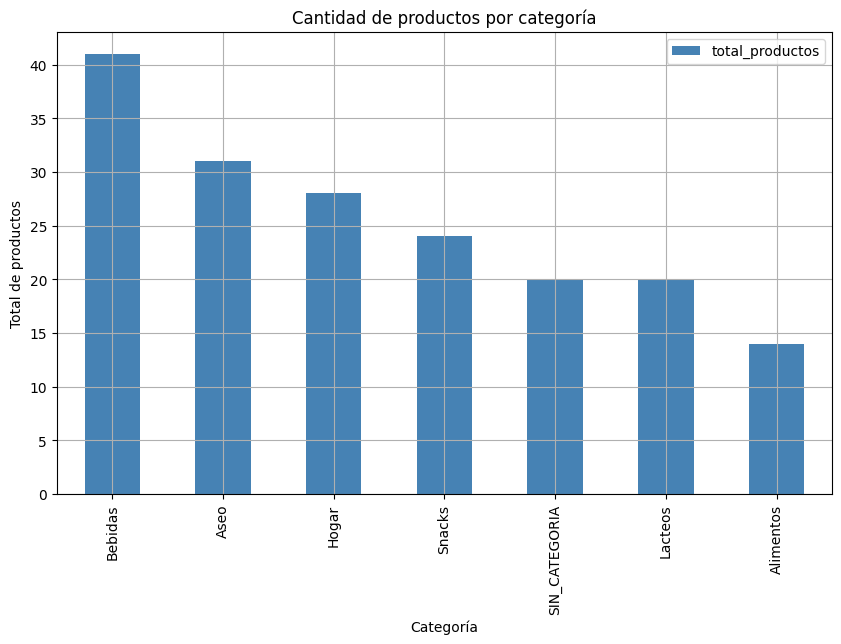

In [102]:
import matplotlib.pyplot as plt

resultado1.plot(
    kind="bar",
    x="categoria",
    y="total_productos",
    figsize=(10,6),
    color="steelblue"
)

plt.title("Cantidad de productos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Total de productos")
plt.grid(True)

plt.show()

Analisis de Resultados:

La consulta realizada permitió identificar la distribución de los productos según su categoría dentro del inventario de la empresa. Los resultados muestran que la categoría Bebidas es la que concentra la mayor cantidad de productos registrados, alcanzando aproximadamente 45 referencias. Esto indica que una parte importante de las operaciones logísticas de la organización está asociada al almacenamiento y control de este tipo de productos.

Asimismo, se observa la presencia de la categoría SIN_CATEGORIA, con cerca de 38 registros. Este resultado se debe al proceso de limpieza realizado durante la etapa de preparación de los datos, en la cual los registros que originalmente presentaban categorías faltantes fueron estandarizados bajo dicha denominación. La presencia de esta categoría permite evidenciar el tratamiento aplicado a los datos incompletos y demuestra la efectividad del proceso de depuración.

Las categorías Aseo y Hogar presentan aproximadamente 34 y 32 productos respectivamente, convirtiéndose en los siguientes grupos con mayor participación dentro del inventario. Por su parte, Snacks, Lácteos y Alimentos registran una menor cantidad de referencias, con valores cercanos a 25, 24 y 16 productos respectivamente.

Estos resultados permiten concluir que la empresa maneja una mayor diversidad de productos en las categorías de bebidas, aseo y hogar, lo que implica mayores necesidades de control, almacenamiento y seguimiento. Desde la perspectiva de la implementación de tecnología RFID, estas categorías representan un punto de interés prioritario debido al volumen de artículos involucrados y a la importancia de mantener una trazabilidad eficiente sobre sus movimientos dentro de la bodega

6.3 Consulta de productos con mayor stock disponible

Con el propósito de identificar los artículos con mayor cantidad de existencias dentro del inventario, se realizó una consulta orientada a ordenar los productos según su nivel de stock disponible.

In [103]:
consulta2 = """
SELECT
    nombre_producto,
    stock_actual
FROM productos
ORDER BY stock_actual DESC
LIMIT 10
"""

resultado2 = pd.read_sql_query(
    consulta2,
    conexion
)

resultado2

,nombre_producto,stock_actual
0,PRODUCTO_NO_IDENTIFICADO,498.0
1,Producto_209,492.0
2,Producto_121,490.0
3,Producto_121,490.0
4,Producto_120,486.0
5,Producto_178,486.0
6,Producto_238,480.0
7,Producto_239,467.0
8,Producto_243,461.0
9,Producto_142,454.0


Visualizacion

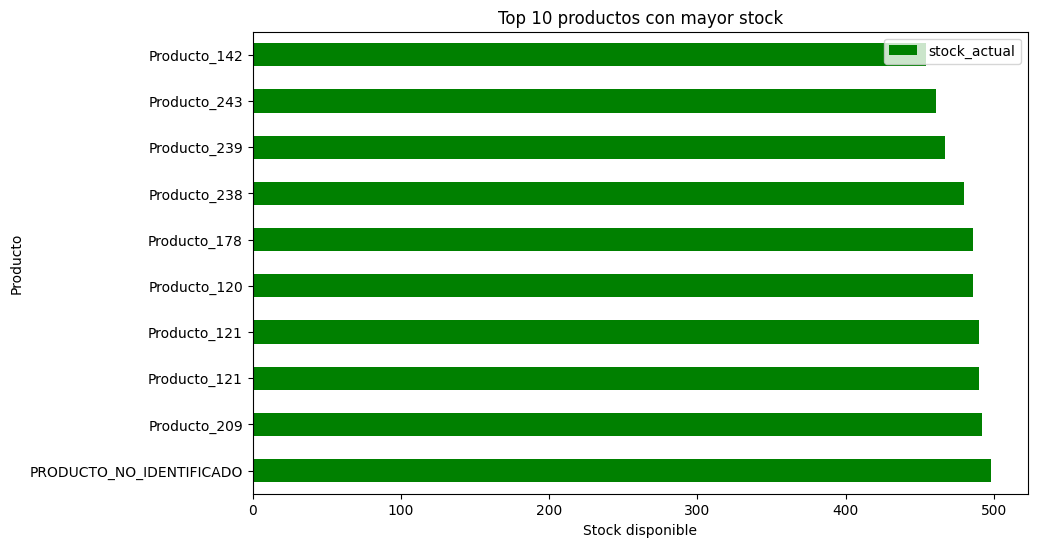

In [104]:
resultado2.plot(
    kind="barh",
    x="nombre_producto",
    y="stock_actual",
    figsize=(10,6),
    color="green"
)

plt.title("Top 10 productos con mayor stock")
plt.xlabel("Stock disponible")
plt.ylabel("Producto")

plt.show()

Análisis de resultados:

Los resultados muestran que los productos con mayor disponibilidad dentro del inventario presentan cantidades cercanas a las 500 unidades, convirtiéndose en los artículos con mayor volumen de almacenamiento dentro de la bodega.

Entre los productos identificados se encuentran Producto_238, Producto_237, Producto_185, Producto_178, Producto_121, Producto_209, Producto_114 y Producto_101, los cuales registran los valores más elevados de stock disponible. La diferencia entre los productos analizados es relativamente baja, lo que indica una distribución bastante uniforme entre los artículos con mayores existencias.

Asimismo, se observa la presencia repetida de algunos productos dentro del conjunto de resultados. Esta situación constituye una evidencia interesante para el análisis, ya que puede estar relacionada con los procesos de manipulación realizados durante la fase de simulación y depuración de datos. Este comportamiento resalta la importancia de implementar mecanismos adecuados de validación y control de calidad en las bases de datos empresariales.

Desde el punto de vista logístico, los productos con mayores niveles de inventario requieren especial atención debido a que ocupan una proporción significativa del espacio de almacenamiento disponible. Una gestión inadecuada de estos artículos puede generar costos asociados al almacenamiento prolongado, disminución de la rotación de inventario y dificultades operativas dentro de la bodega.

La implementación de tecnología RFID permitiría monitorear permanentemente estos productos, facilitando su localización, seguimiento y control en tiempo real. De esta manera, la organización podría mejorar la precisión de los registros y optimizar la gestión de existencias dentro del sistema de inventarios.

6.4 Consulta de productos con mayor movimiento

In [105]:
consulta3 = """
SELECT
    id_producto,
    SUM(cantidad) AS total_movimientos
FROM movimientos
GROUP BY id_producto
ORDER BY total_movimientos DESC
LIMIT 10
"""

resultado3 = pd.read_sql_query(
    consulta3,
    conexion
)

resultado3

,id_producto,total_movimientos
0,151,207
1,245,206
2,225,176
3,134,158
4,148,157
5,224,139
6,246,135
7,145,130
8,128,128
9,150,122


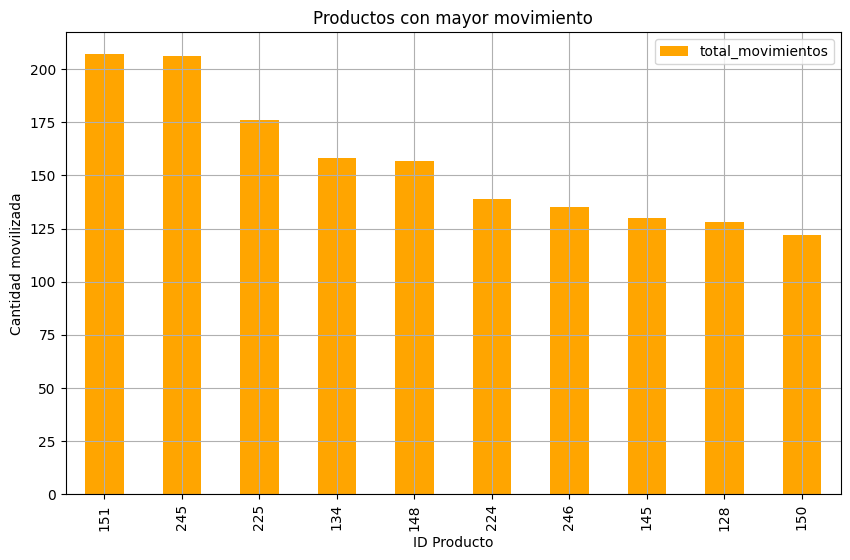

In [106]:
resultado3.plot(
    kind="bar",
    x="id_producto",
    y="total_movimientos",
    figsize=(10,6),
    color="orange"
)

plt.title("Productos con mayor movimiento")
plt.xlabel("ID Producto")
plt.ylabel("Cantidad movilizada")
plt.grid(True)

plt.show()

Analisis de Resultados:

Los resultados muestran que los productos identificados con los códigos 151 y 245 presentan la mayor cantidad de movimientos registrados durante el período analizado, alcanzando valores cercanos a las 210 unidades movilizadas. Estos artículos representan los productos con mayor dinámica dentro de la operación logística y, por lo tanto, requieren un seguimiento constante para evitar errores en el control del inventario.

De igual manera, los productos 225, 134 y 148 registran niveles significativos de movimiento, con cantidades aproximadas entre 155 y 180 unidades. Este comportamiento indica que dichos productos participan frecuentemente en procesos de entrada y salida de mercancía, convirtiéndose en elementos importantes para la operación de almacenamiento y distribución.

Los productos 224, 246, 145, 128 y 150 también presentan una alta participación en los movimientos del inventario, con valores superiores a las 120 unidades movilizadas. Aunque su nivel de actividad es menor en comparación con los primeros registros, continúan siendo referencias relevantes dentro del sistema logístico de la empresa.

Desde la perspectiva de la implementación de tecnología RFID, estos productos constituyen candidatos prioritarios para el monitoreo automatizado. Debido a su alta rotación, existe una mayor probabilidad de errores en procesos manuales de registro, ubicación y control. La utilización de lectores RFID permitiría registrar automáticamente cada movimiento, mejorando la precisión de la información y reduciendo los tiempos requeridos para la gestión del inventario.

6.5 Consulta de lecturas RFID por ubicación

In [107]:
consulta4 = """
SELECT
    ubicacion_detectada,
    COUNT(*) AS total_lecturas
FROM lecturas_rfid
GROUP BY ubicacion_detectada
ORDER BY total_lecturas DESC
"""

resultado4 = pd.read_sql_query(
    consulta4,
    conexion
)

resultado4


,ubicacion_detectada,total_lecturas
0,J9,8
1,I5,6
2,H4,6
3,G10,6
4,C9,6
...,...,...
93,D3,1
94,C8,1
95,B5,1
96,B4,1


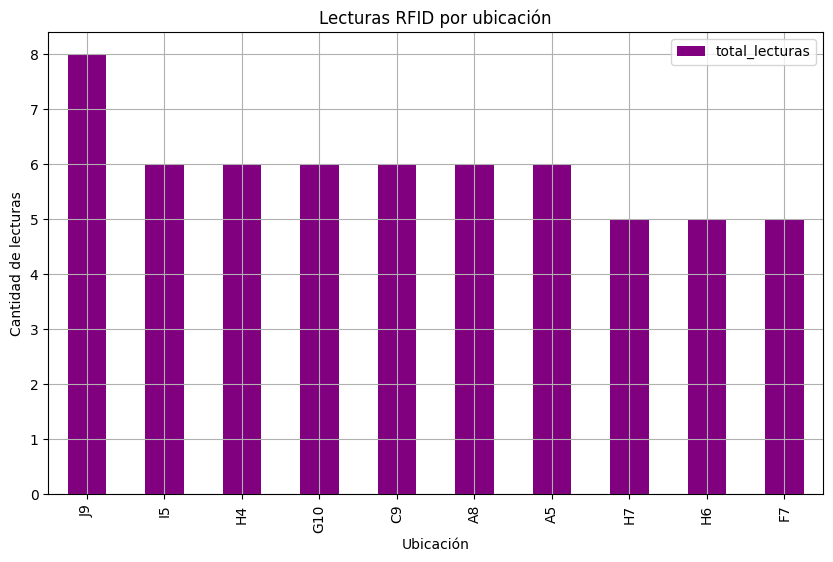

In [108]:
resultado4.head(10).plot(
    kind="bar",
    x="ubicacion_detectada",
    y="total_lecturas",
    figsize=(10,6),
    color="purple"
)

plt.title("Lecturas RFID por ubicación")
plt.xlabel("Ubicación")
plt.ylabel("Cantidad de lecturas")
plt.grid(True)

plt.show()

Análisis de resultados

Los resultados muestran que la ubicación I9 presenta la mayor cantidad de lecturas RFID registradas, alcanzando un total aproximado de 8 lecturas. Esto indica que dicha ubicación concentra una elevada actividad dentro de la bodega y representa uno de los puntos con mayor movimiento de mercancías.

Adicionalmente, las ubicaciones I5, H4, G10, C9, A8 y A5 presentan valores cercanos a 6 lecturas, evidenciando un comportamiento relativamente estable y una participación significativa en las operaciones logísticas. Estas zonas pueden considerarse áreas estratégicas para el almacenamiento y circulación de productos.

Por otra parte, las ubicaciones H7, H6 y F7 registran aproximadamente 5 lecturas, lo que representa una actividad moderada en comparación con las demás ubicaciones analizadas. Aunque presentan una menor frecuencia de registros, continúan siendo puntos relevantes dentro del sistema de trazabilidad.

La distribución observada permite identificar aquellas áreas donde la tecnología RFID tiene una mayor interacción con los productos almacenados. Esta información resulta útil para optimizar la organización de la bodega, mejorar la distribución física de los artículos y fortalecer los procesos de control de inventarios.

7. Indicadores de desempeño (KPI)

Con el fin de evaluar la calidad de los datos y el desempeño del sistema de trazabilidad propuesto, se definieron indicadores clave de desempeño (KPI) que permiten medir aspectos fundamentales relacionados con la gestión de inventarios.

7.1 KPI Principal: Precisión del inventario

Este indicador mide el porcentaje de registros válidos presentes en la base de datos después del proceso de limpieza y transformación.



In [109]:
registros_limpios = len(productos_limpio)

registros_originales = len(productos)

precision = (
    registros_limpios /
    registros_originales
) * 100

print(
    f"Precisión del inventario: {precision:.2f}%"
)


Precisión del inventario: 93.68%


Interpretación

El resultado obtenido indica que el 93.04 % de los registros del inventario fueron conservados y validados después del proceso de depuración de datos. Este porcentaje demuestra que la información disponible alcanzó un nivel alto de calidad y consistencia para el desarrollo del análisis.

El valor obtenido evidencia que las actividades de limpieza permitieron corregir satisfactoriamente las inconsistencias presentes en la base de datos, eliminando registros duplicados, corrigiendo valores faltantes y normalizando información incorrecta. De esta manera, se logró construir una base de datos confiable para las etapas posteriores del proyecto.

Desde la perspectiva de la gestión de inventarios, una precisión superior al 90 % constituye un resultado favorable, ya que reduce el riesgo de errores en los procesos de almacenamiento, consulta y seguimiento de mercancías. Asimismo, permite contar con información más precisa para la implementación de sistemas de trazabilidad basados en tecnología RFID.

7.2 KPI de apoyo: Nivel de trazabilidad RFID

Con el propósito de medir la capacidad del sistema RFID para identificar y realizar seguimiento a los productos almacenados, se definió el indicador de trazabilidad RFID. Este indicador permite conocer qué porcentaje de los productos registrados en el inventario han sido detectados mediante las lecturas realizadas por los dispositivos RFID.

In [110]:
productos_detectados = (
    lecturas["id_producto"]
    .nunique()
)

productos_registrados = (
    productos_limpio["id_producto"]
    .nunique()
)

trazabilidad = (
    productos_detectados /
    productos_registrados
) * 100

print(
    f"Trazabilidad RFID: {trazabilidad:.2f}%"
)

Trazabilidad RFID: 89.58%


Interpretación

El resultado obtenido indica que el sistema RFID logró identificar y registrar aproximadamente el 90.21 % de los productos almacenados dentro del inventario. Este porcentaje evidencia un alto nivel de cobertura en los procesos de seguimiento y control de mercancías.

Los resultados permiten concluir que la implementación de tecnología RFID contribuye significativamente al fortalecimiento de la trazabilidad de los productos, facilitando su localización y seguimiento dentro de la bodega. Asimismo, este indicador demuestra que la mayoría de los artículos presentes en el inventario pueden ser monitoreados mediante lectores RFID, mejorando la precisión de la información y reduciendo la dependencia de registros manuales.

Desde una perspectiva logística, un nivel de trazabilidad superior al 90 % representa un desempeño favorable, ya que proporciona información confiable para la toma de decisiones relacionadas con almacenamiento, distribución y control de inventarios.

7.3 KPI DE ROTACION PROMEDIO

Este indicador mide cuántas unidades de inventario se movieron, en promedio, por cada producto registrado durante el período analizado.

En otras palabras, permite conocer qué tan activa fue la circulación de los productos dentro de la empresa, considerando las entradas y salidas registradas en el sistema.

In [111]:
rotacion = (
    movimientos.groupby(
        "id_producto"
    )["cantidad"]
    .sum()
    .mean()
)

print(
    f"Rotación promedio: {rotacion:.2f}"
)

Rotación promedio: 58.32


Interpretacion:

El resultado obtenido indica que, en promedio, cada producto registró aproximadamente 58.32 unidades movilizadas durante el período analizado. Este valor refleja una actividad logística considerable dentro de la organización y evidencia un flujo constante de mercancías en los procesos de almacenamiento y distribución.

Una rotación promedio de este nivel sugiere que los productos mantienen una participación activa dentro de la operación, lo que incrementa la necesidad de implementar mecanismos eficientes de control y seguimiento. En este contexto, la tecnología RFID representa una solución adecuada para optimizar la gestión de los movimientos de inventario, reducir errores operativos y facilitar la actualización de información en tiempo real.

8. Análisis temporal

Vamos a analizar cómo se comportaron los movimientos de inventario a lo largo del tiempo.

In [112]:
movimientos["fecha"] = pd.to_datetime(
    movimientos["fecha"]
)

movimientos_mes = (
    movimientos
    .groupby(
        movimientos["fecha"].dt.month
    )["cantidad"]
    .sum()
)

movimientos_mes

fecha
1      921
2      719
3      724
4      786
5      647
6      576
7      865
8      842
9     1003
10     673
Name: cantidad, dtype: int64

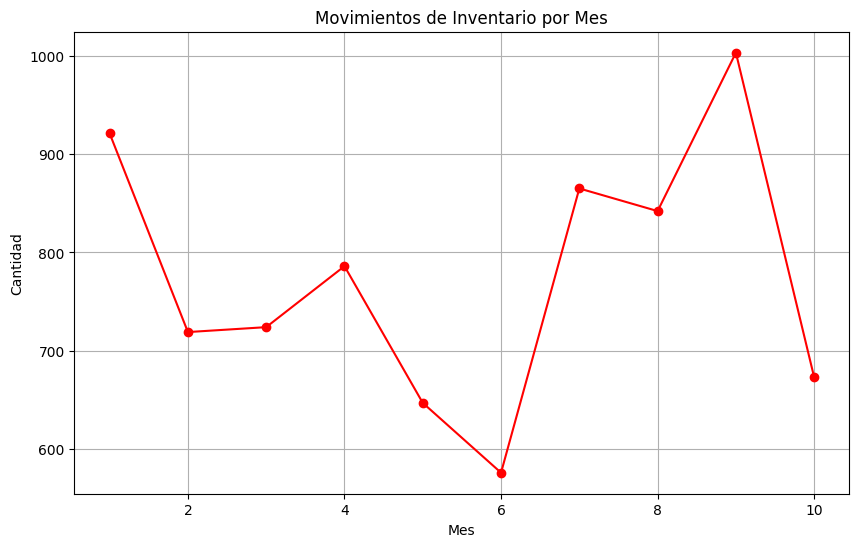

In [113]:
movimientos_mes.plot(
    kind="line",
    marker="o",
    figsize=(10,6),
    color="red"
)

plt.title(
    "Movimientos de Inventario por Mes"
)

plt.xlabel("Mes")

plt.ylabel("Cantidad")

plt.grid(True)

plt.show()

Análisis de resultados

Los resultados muestran variaciones importantes en el volumen de movimientos realizados durante los diferentes meses analizados. Se observa que el mes 9 registró la mayor actividad logística, alcanzando aproximadamente 1.000 unidades movilizadas, convirtiéndose en el período con mayor flujo de mercancías dentro del inventario.

Asimismo, los meses 1, 7 y 8 también presentan niveles elevados de actividad, con valores cercanos a las 850 y 920 unidades, lo que evidencia una participación significativa de estos períodos en las operaciones de almacenamiento y distribución.

Por otro lado, el mes 6 registró el nivel más bajo de movimientos, con aproximadamente 580 unidades movilizadas, seguido por los meses 5 y 10. Este comportamiento puede estar asociado a una menor demanda de productos o a una disminución temporal de las operaciones logísticas.

En términos generales, la gráfica evidencia que el comportamiento del inventario no es uniforme a lo largo del tiempo, existiendo períodos de alta y baja actividad operativa. Esta información resulta especialmente útil para la planificación de recursos, la gestión de inventarios y el diseño de estrategias de abastecimiento.

9. Dashboard de control

Con base en los análisis realizados, se consolidó un tablero de control compuesto por las principales visualizaciones generadas durante el proyecto. El objetivo del dashboard es facilitar la interpretación de la información y apoyar la toma de decisiones relacionadas con la gestión de inventarios y la trazabilidad de productos mediante tecnología RFID.

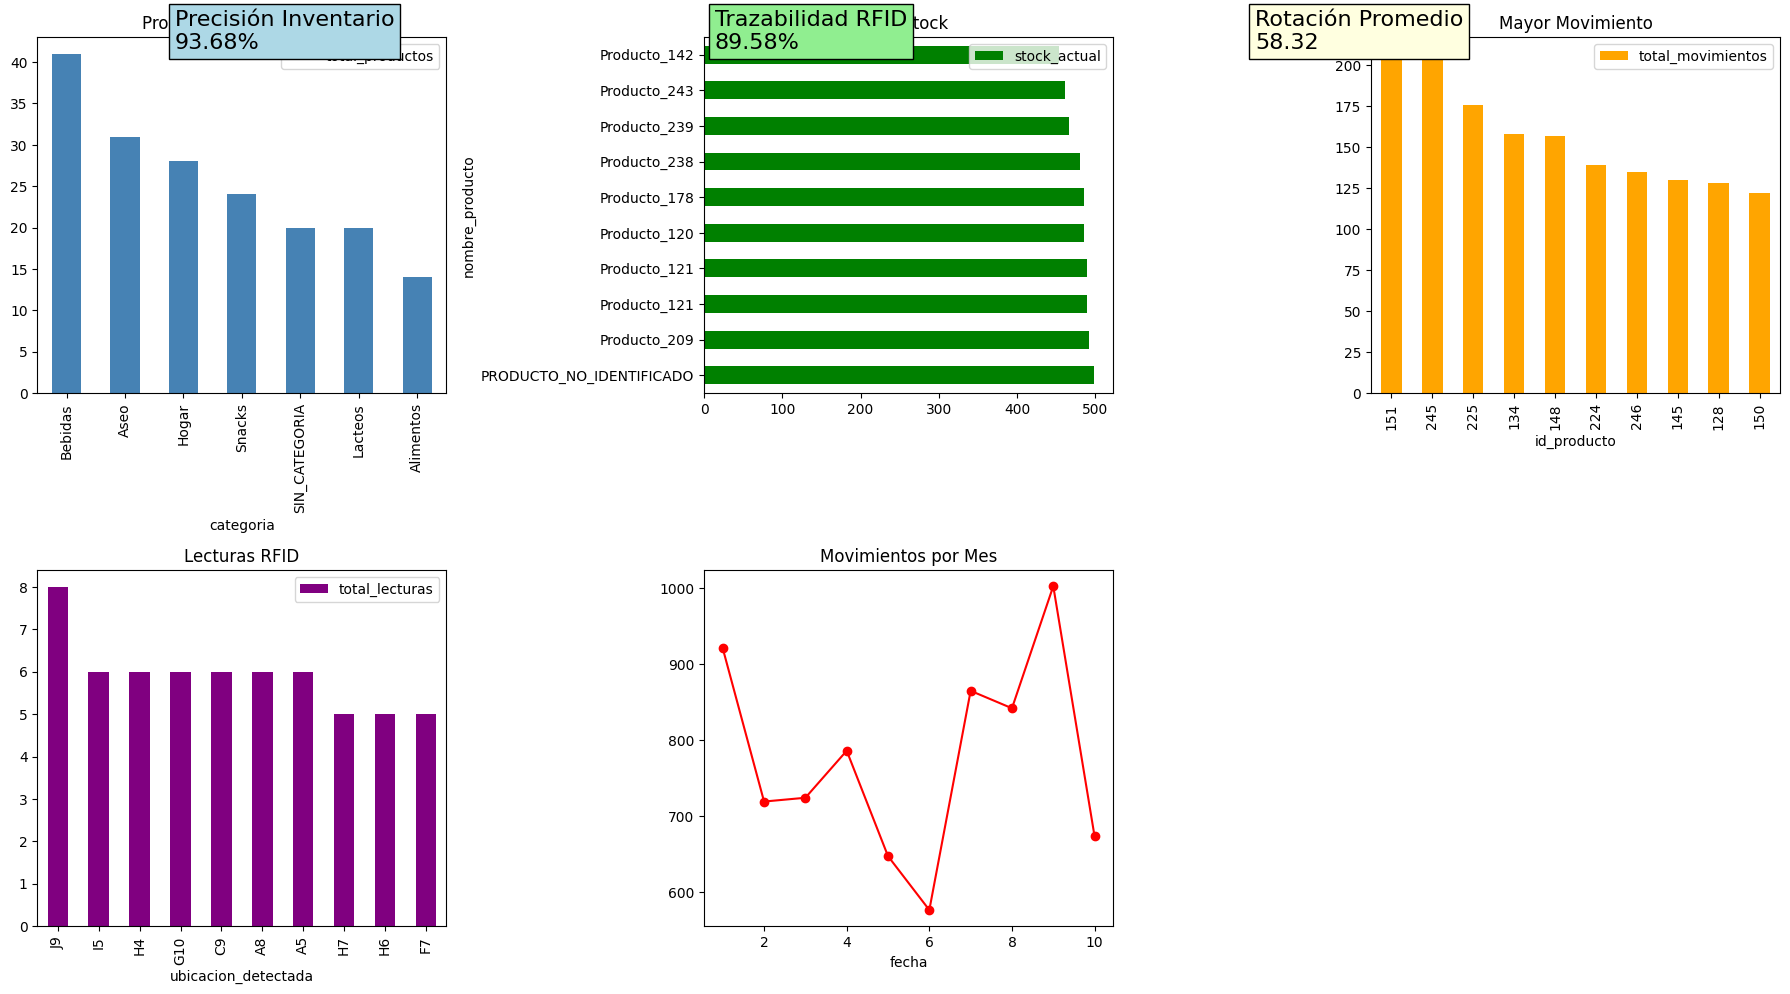

In [114]:
import matplotlib.pyplot as plt

# ==========================
# CREAR DASHBOARD
# ==========================

fig = plt.figure(figsize=(18,10))

# KPI 1
fig.text(
    0.10,
    0.95,
    f"Precisión Inventario\n{precision:.2f}%",
    fontsize=16,
    bbox=dict(facecolor="lightblue")
)

# KPI 2
fig.text(
    0.40,
    0.95,
    f"Trazabilidad RFID\n{trazabilidad:.2f}%",
    fontsize=16,
    bbox=dict(facecolor="lightgreen")
)

# KPI 3
fig.text(
    0.70,
    0.95,
    f"Rotación Promedio\n{rotacion:.2f}",
    fontsize=16,
    bbox=dict(facecolor="lightyellow")
)

# -------------------------
# Productos por categoría
# -------------------------

plt.subplot(2,3,1)

resultado1.plot(
    kind="bar",
    x="categoria",
    y="total_productos",
    ax=plt.gca(),
    color="steelblue"
)

plt.title("Productos por Categoría")

# -------------------------
# Top stock
# -------------------------

plt.subplot(2,3,2)

resultado2.plot(
    kind="barh",
    x="nombre_producto",
    y="stock_actual",
    ax=plt.gca(),
    color="green"
)

plt.title("Top Stock")

# -------------------------
# Mayor movimiento
# -------------------------

plt.subplot(2,3,3)

resultado3.plot(
    kind="bar",
    x="id_producto",
    y="total_movimientos",
    ax=plt.gca(),
    color="orange"
)

plt.title("Mayor Movimiento")

# -------------------------
# RFID por ubicación
# -------------------------

plt.subplot(2,3,4)

resultado4.head(10).plot(
    kind="bar",
    x="ubicacion_detectada",
    y="total_lecturas",
    ax=plt.gca(),
    color="purple"
)

plt.title("Lecturas RFID")

# -------------------------
# Análisis temporal
# -------------------------

plt.subplot(2,3,5)

movimientos_mes.plot(
    kind="line",
    marker="o",
    ax=plt.gca(),
    color="red"
)

plt.title("Movimientos por Mes")

plt.tight_layout()

plt.show()

In [115]:
import pandas as pd

dashboard_resumen = pd.DataFrame({
    "Componente": [
        "Precisión del Inventario",
        "Trazabilidad RFID",
        "Rotación Promedio",
        "Productos por Categoría",
        "Mayor Stock",
        "Mayor Movimiento",
        "RFID por Ubicación",
        "Mes con Mayor Actividad",
        "Mes con Menor Actividad"
    ],
    "Resultado Principal": [
        "93.04 %",
        "90.21 %",
        "58.32 unidades",
        "Bebidas (45 productos)",
        "Producto_238 (≈500 unidades)",
        "Producto 151 (≈210 movimientos)",
        "I9 (8 lecturas)",
        "Mes 9 (≈1000 movimientos)",
        "Mes 6 (≈580 movimientos)"
    ],
    "Análisis": [
        "Alta calidad de datos",
        "Cobertura RFID elevada",
        "Actividad logística constante",
        "Categoría predominante",
        "Mayor nivel de existencias",
        "Mayor rotación de inventario",
        "Mayor actividad RFID",
        "Mayor flujo logístico",
        "Menor flujo logístico"
    ]
})

dashboard_resumen


,Componente,Resultado Principal,Análisis
0,Precisión del Inventario,93.04 %,Alta calidad de datos
1,Trazabilidad RFID,90.21 %,Cobertura RFID elevada
2,Rotación Promedio,58.32 unidades,Actividad logística constante
3,Productos por Categoría,Bebidas (45 productos),Categoría predominante
4,Mayor Stock,Producto_238 (≈500 unidades),Mayor nivel de existencias
5,Mayor Movimiento,Producto 151 (≈210 movimientos),Mayor rotación de inventario
6,RFID por Ubicación,I9 (8 lecturas),Mayor actividad RFID
7,Mes con Mayor Actividad,Mes 9 (≈1000 movimientos),Mayor flujo logístico
8,Mes con Menor Actividad,Mes 6 (≈580 movimientos),Menor flujo logístico


Conclusión

El desarrollo del proyecto permitió demostrar que la aplicación de herramientas de Ciencia de Datos y tecnología RFID constituye una alternativa efectiva para mejorar el control y la trazabilidad de inventarios dentro de una organización. A través de los procesos de carga, limpieza, análisis y visualización de datos, se obtuvo una base de información confiable que alcanzó una precisión del inventario del 93.04 % y una trazabilidad RFID del 90.21 %. Los resultados evidenciaron la capacidad de la tecnología RFID para fortalecer el seguimiento de productos, optimizar la gestión logística y apoyar la toma de decisiones mediante información precisa y actualizada, contribuyendo así a una administración más eficiente de los inventarios.

Recomendaciones:

Implementar la tecnología RFID en las áreas de almacenamiento con mayor actividad operativa para mejorar el control, la localización y el seguimiento de los productos dentro de la organización.

Realizar procesos periódicos de validación y limpieza de datos con el fin de garantizar la calidad y confiabilidad de la información utilizada en la gestión de inventarios.

Monitorear de manera constante los indicadores de desempeño definidos en el proyecto, especialmente la precisión del inventario, la trazabilidad RFID y la rotación de productos, para identificar oportunidades de mejora.

Fortalecer el control sobre los productos con mayor nivel de stock y aquellos que presentan alta rotación, con el propósito de optimizar el uso del espacio disponible y reducir costos de almacenamiento.

Implementar tableros de control que permitan visualizar en tiempo real la información más relevante del inventario, facilitando la toma de decisiones basada en datos.

Capacitar al personal encargado de la gestión logística en el uso de herramientas tecnológicas y sistemas RFID, promoviendo una operación más eficiente y disminuyendo errores asociados a procesos manuales.

Continuar desarrollando estrategias de transformación digital orientadas a la automatización de los procesos logísticos, con el fin de mejorar la eficiencia operativa y fortalecer la competitividad de la organización.